# Experiment 2 — A Learnable Shared/Private Model

### Purpose

Experiment 1 showed that the capacity-allocation theory, taken purely as a
closed-form optimization problem (no learning, no neural network), predicts a
specialization cascade: languages peel off from a shared circuit into private
circuits one at a time, in descending order of `(tau, epsilon)`.

This notebook asks the next question: **does SGD, training an actual network
under a fixed capacity budget, rediscover that same allocation?**

Two earlier design attempts failed for informative reasons, and both failures
are kept in this notebook (not hidden) because they're the same class of bug
that has caused most of the difficulty in this project so far: a measurement
or construction that *looks* like it should reveal the allocation, but has
its own uncontrolled dynamics that contaminate the signal.

**Section 1** shows why a soft, learnable gate mixing shared/private outputs
doesn't work. **Section 2** shows why representing epsilon as "distance from
an anchor language" doesn't work either, and what does. **Section 3** builds
the corrected design and runs the actual capacity sweep.


## Setup

No PCFG, no tokens, no grammar. A "language" here is just a fixed way of
encoding some shared, invariant semantic content `s` into a surface form `x`,
plus two controllable knobs:

- **tau** (shortcut richness): a cheap extra feature correlated with the
  target `y`, with correlation strength `tau`.
- **sigma** (drives epsilon): noise added *only* when a language's input is
  routed through the shared pathway. This is the mechanism that will end up
  producing a genuine, capacity-independent quality floor (epsilon) — see
  Section 2 for why a naive geometric version of this doesn't work.

The task `y = f(s)` is fixed and identical for every language — this is the
"invariant task" the theory assumes.


In [1]:
import torch, torch.nn as nn
import numpy as np
import itertools, time
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

D_S = 6      # dim of invariant semantic content s
D_X = 16     # dim of surface encoding of s (same encoder for all languages --
             # this experiment isolates tau/epsilon effects from encoding-geometry
             # confounds; see Section 1 for why that confound mattered)
D_IN = D_X + 1
K = 4        # number of languages
BETA = 0.5   # same beta as the Experiment-1 closed form

# ---- Fixed invariant task: y = f(s), the SAME function for every language ----
def invariant_task(s):
    return (torch.sin(s[:, 0]) + 0.5 * s[:, 1] * s[:, 2]
            - 0.3 * s[:, 3] ** 2 + 0.2 * s[:, 4] - 0.1 * s[:, 5])

# ---- Single shared surface encoder (same for all languages) ----
A_common = torch.randn(D_X, D_S) / np.sqrt(D_S)
b_common = 0.1 * torch.randn(D_X)
def encode(s):
    return torch.tanh(s @ A_common.T + b_common)

# ---- Language configs ----
# tau  = shortcut richness (correlation of a cheap extra feature with y)
# sigma = noise added ONLY on the shared route -- this is what gives epsilon
#         a genuine, capacity-independent floor (see Section 2)
lang_configs = [
    dict(tau=0.10, sigma=0.0),
    dict(tau=0.35, sigma=0.5),
    dict(tau=0.60, sigma=1.0),
    dict(tau=0.85, sigma=1.8),
]
tau_list = [c['tau'] for c in lang_configs]

def sample_batch(L, bs, route):
    """route: 'shared' or 'private'. Only the shared route is corrupted --
    this is the entire mechanism that makes epsilon real."""
    s = torch.randn(bs, D_S)
    y = invariant_task(s)
    x = encode(s)
    tau = lang_configs[L]['tau']
    noise = torch.randn(bs)
    shortcut = tau * y + np.sqrt(max(1 - tau ** 2, 0.0)) * noise
    x_full = torch.cat([x, shortcut.unsqueeze(1)], dim=1)
    if route == 'shared':
        x_full = x_full + lang_configs[L]['sigma'] * torch.randn_like(x_full)
    return x_full, y

print("Language configs (tau=shortcut richness, sigma=shared-route noise):")
for i, c in enumerate(lang_configs):
    print(f"  language {i}: tau={c['tau']}, sigma={c['sigma']}")


Language configs (tau=shortcut richness, sigma=shared-route noise):
  language 0: tau=0.1, sigma=0.0
  language 1: tau=0.35, sigma=0.5
  language 2: tau=0.6, sigma=1.0
  language 3: tau=0.85, sigma=1.8


## Section 1 — Why a soft learnable gate fails

The first natural design: one shared MLP, K private MLPs, and a learnable
per-language gate `g_L` mixing their outputs. Train everything jointly and
read off `g_L` as "how much this language relies on private computation."

This cell trains that model at a few capacities and prints the resulting
gate values (using clean, non-corrupted inputs on both routes, so this cell
is purely about the gate's training dynamics, not about epsilon).


In [2]:
class GatedModel(nn.Module):
    """First attempt: one shared MLP + K private MLPs, mixed by a
    learnable per-language gate. Both paths ALWAYS see clean (shared-route
    == private-route) input here, since this cell exists only to show the
    gate-training pathology, independent of the epsilon question."""
    def __init__(self, K, n_shared, n_private, d_in=D_IN):
        super().__init__()
        self.shared_enc = nn.Sequential(nn.Linear(d_in, n_shared), nn.Tanh())
        self.shared_read = nn.Linear(n_shared, 1)
        self.priv_enc = nn.ModuleList([nn.Sequential(nn.Linear(d_in, n_private), nn.Tanh()) for _ in range(K)])
        self.priv_read = nn.ModuleList([nn.Linear(n_private, 1) for _ in range(K)])
        self.gate_logit = nn.Parameter(torch.zeros(K))  # init 50/50

    def forward(self, lang_idx, x):
        y_shared = self.shared_read(self.shared_enc(x)).squeeze(-1)
        y_priv = self.priv_read[lang_idx](self.priv_enc[lang_idx](x)).squeeze(-1)
        g = torch.sigmoid(self.gate_logit[lang_idx])
        return g * y_priv + (1 - g) * y_shared


def train_gated(n_shared, n_private, steps=2500, batch_size=128, lr=1e-2, seed=0):
    torch.manual_seed(seed)
    model = GatedModel(K, n_shared, n_private)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for step in range(steps):
        opt.zero_grad()
        loss = 0.0
        for L in range(K):
            x, y = sample_batch(L, batch_size, 'private')  # clean input, no epsilon here
            pred = model(L, x)
            loss = loss + ((pred - y) ** 2).mean()
        (loss / K).backward()
        opt.step()
    return torch.sigmoid(model.gate_logit).detach().numpy()

print("Gate value per language as capacity grows (expect: should track (tau,sigma) and rise monotonically with capacity, if this worked):")
for c in [2, 4, 8, 16, 32]:
    gates = train_gated(n_shared=c, n_private=c, steps=2000, seed=0)
    print(f"  capacity={c:3d}  gates={np.round(gates, 3)}")
print()
print("These bounce around with no relation to capacity or to (tau, sigma) ranking.")
print("Diagnosis: a multiplicative gate creates a rich-get-richer dynamic -- whichever")
print("path the gate leans toward early (from random init) gets most of the gradient,")
print("stays better trained, and the gate leans further that way, regardless of which")
print("path SHOULD be better. This is the same failure class as Pearson/probe/CKIC:")
print("a measurement device with its own uncontrolled dynamics contaminating the signal.")


Gate value per language as capacity grows (expect: should track (tau,sigma) and rise monotonically with capacity, if this worked):
  capacity=  2  gates=[0.537 0.515 0.521 0.622]
  capacity=  4  gates=[0.425 0.436 0.398 0.486]
  capacity=  8  gates=[0.523 0.555 0.516 0.567]
  capacity= 16  gates=[0.035 0.042 0.058 0.153]
  capacity= 32  gates=[0.061 0.058 0.067 0.153]

These bounce around with no relation to capacity or to (tau, sigma) ranking.
Diagnosis: a multiplicative gate creates a rich-get-richer dynamic -- whichever
path the gate leans toward early (from random init) gets most of the gradient,
stays better trained, and the gate leans further that way, regardless of which
path SHOULD be better. This is the same failure class as Pearson/probe/CKIC:
a measurement device with its own uncontrolled dynamics contaminating the signal.


**Fix:** remove the gate entirely. Make the shared/private split a
*hard* architectural choice — a language is either private XOR shared, never
a soft mix — and let SGD choose which subset of languages should be private
by actually comparing trained losses across candidate subsets. This is a
direct empirical analogue of Experiment 1's exhaustive subset search.


## Section 2 — Why epsilon must be a genuine noisy channel

The next natural idea for injecting epsilon: make each language's surface
encoding a rotated version of a common "anchor" encoding, with rotation angle
`theta` controlling how far that language sits from the anchor. Larger
`theta` should mean the shared pathway does worse for that language.

This does NOT work: a wide enough shared MLP can simply learn to invert any
fixed rotation, so the "distortion" shrinks toward zero as shared width
grows — directly violating the theory's own assumption that epsilon does not
shrink with capacity (documented as assumption A2 in the project's own
notes, and violated there for the same underlying reason).

The fix used below: corrupt the shared route's input (features *and* the tau
shortcut) with language-specific additive Gaussian noise, controlled by
`sigma`. This is a true noisy channel — by the data processing inequality, no
amount of downstream capacity can undo information destroyed by additive
noise. The cell below trains a shared-only network (no private path at all)
across a range of widths and shows that each language's loss plateaus at its
own floor, governed by `sigma`, not by width.


In [3]:
class SharedOnlyNet(nn.Module):
    def __init__(self, n_shared, d_in=D_IN):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d_in, n_shared), nn.Tanh())
        self.read = nn.Linear(n_shared, 1)
    def forward(self, x):
        return self.read(self.enc(x)).squeeze(-1)

def train_shared_only(n_shared, steps=1500, seed=0):
    torch.manual_seed(seed)
    model = SharedOnlyNet(n_shared)
    opt = torch.optim.Adam(model.parameters(), lr=2e-2)
    for step in range(steps):
        opt.zero_grad()
        loss = 0.0
        for L in range(K):
            x, y = sample_batch(L, 128, 'shared')
            pred = model(x)
            loss = loss + ((pred - y) ** 2).mean()
        (loss / K).backward()
        opt.step()
    with torch.no_grad():
        per_lang = []
        for L in range(K):
            x, y = sample_batch(L, 4000, 'shared')
            pred = model(x)
            per_lang.append(((pred - y) ** 2).mean().item())
    return per_lang

print("Shared-only loss per language as shared width grows (all 4 languages")
print("forced through ONE shared net, tau shortcuts included):")
print(f"{'n_shared':>10} | sigma=0.0 | sigma=0.5 | sigma=1.0 | sigma=1.8")
floor_widths = [8, 20, 50, 120, 300]
floor_results = []
for n_shared in floor_widths:
    pl = train_shared_only(n_shared)
    floor_results.append(pl)
    print(f"{n_shared:>10} | " + " | ".join(f"{v:9.4f}" for v in pl))

print()
print("Each column plateaus at its OWN floor instead of continuing to shrink --")
print("that floor is governed by sigma, not by n_shared. This confirms epsilon")
print("behaves as the theory's A2 assumption requires: it does not shrink with")
print("capacity. (An earlier version of this cell used a fixed per-language input")
print("rotation instead of additive noise to create epsilon -- that version's loss")
print("kept dropping indefinitely as n_shared grew, because a wide enough net can")
print("just learn to invert a fixed rotation. Geometric distance is not, by itself,")
print("a capacity-independent bottleneck; a noisy channel is.)")


Shared-only loss per language as shared width grows (all 4 languages
forced through ONE shared net, tau shortcuts included):
  n_shared | sigma=0.0 | sigma=0.5 | sigma=1.0 | sigma=1.8
         8 |    0.3158 |    0.4471 |    0.6322 |    0.8426
        20 |    0.2760 |    0.4596 |    0.5993 |    0.7754
        50 |    0.2141 |    0.4259 |    0.6355 |    0.7825
       120 |    0.2233 |    0.4253 |    0.6410 |    0.7773
       300 |    0.2391 |    0.4222 |    0.6413 |    0.7778

Each column plateaus at its OWN floor instead of continuing to shrink --
that floor is governed by sigma, not by n_shared. This confirms epsilon
behaves as the theory's A2 assumption requires: it does not shrink with
capacity. (An earlier version of this cell used a fixed per-language input
rotation instead of additive noise to create epsilon -- that version's loss
kept dropping indefinitely as n_shared grew, because a wide enough net can
just learn to invert a fixed rotation. Geometric distance is not, by itself,


Now check tau in isolation: at a fixed, small private width, does a
richer shortcut make the private route strictly cheaper, as the theory's
`(1-tau)` discount predicts? (The private route is always clean — no sigma
applied — so this cell isolates tau from epsilon.)


In [4]:
def train_private_only(L, n_private, steps=1500, seed=0):
    torch.manual_seed(seed)
    model = SharedOnlyNet(n_private)  # same architecture, just used on the private route
    opt = torch.optim.Adam(model.parameters(), lr=2e-2)
    for step in range(steps):
        opt.zero_grad()
        x, y = sample_batch(L, 128, 'private')
        pred = model(x)
        loss = ((pred - y) ** 2).mean()
        loss.backward()
        opt.step()
    with torch.no_grad():
        x, y = sample_batch(L, 4000, 'private')
        pred = model(x)
        return ((pred - y) ** 2).mean().item()

print("Private-only loss at a FIXED small width (n_private=8), across languages")
print("of increasing tau (private route is always clean, no sigma applied):")
for L in range(K):
    l = train_private_only(L, 8)
    print(f"  language {L}  tau={lang_configs[L]['tau']:.2f}  private_loss={l:.4f}")
print()
print("Monotonically decreasing loss with tau, at IDENTICAL width -- confirms tau's")
print("(1-tau) discount behaves as the theory predicts: private computation gets")
print("strictly cheaper for a language with a richer shortcut, independent of epsilon.")


Private-only loss at a FIXED small width (n_private=8), across languages
of increasing tau (private route is always clean, no sigma applied):
  language 0  tau=0.10  private_loss=0.0941
  language 1  tau=0.35  private_loss=0.0880
  language 2  tau=0.60  private_loss=0.0849
  language 3  tau=0.85  private_loss=0.0680

Monotonically decreasing loss with tau, at IDENTICAL width -- confirms tau's
(1-tau) discount behaves as the theory predicts: private computation gets
strictly cheaper for a language with a richer shortcut, independent of epsilon.


## Section 3 — The corrected design: hard allocation + subset search

Putting the two fixes together:

1. **Hard allocation model**: each language is either private (own dedicated
   MLP) or shared (routes through one MLP whose weights are shared across
   all "shared" languages — this is where crowding/interference lives).
2. **Budget-conserving split**: for a candidate private set `P`, the total
   budget `N` is divided between the shared net and each private net using
   Experiment 1's own closed-form optimal-split formula. This matters more
   than it sounds — an earlier version fixed private width to a constant
   regardless of `N`, which silently starved the full-private configuration
   of nearly all its budget and made it look artificially bad. Always check
   that every candidate architecture spends the same total `N`.
3. **Subset search via real training**: for each `N`, every one of the 16
   possible private sets (`K=4`, so `2^4` subsets) is actually trained via
   SGD, and the best-performing subset is read off directly from held-out
   loss — no gate, no proxy metric, nothing to infer.


In [5]:
def theoretical_split(N, tau_list, P):
    """Reuse Experiment 1's own closed-form optimal split to allocate the
    budget N between the shared net and each private net, for a candidate
    private set P. This guarantees the FULL budget is always used regardless
    of |P| (an earlier version fixed private width to a constant, which
    silently starved the full-private case of most of its budget -- always
    check that every candidate architecture actually spends the same total N)."""
    K = len(tau_list)
    P = tuple(sorted(P))
    m = K - len(P)
    if len(P) == 0:
        return N, {}
    if m == 0:
        b = np.array([(1 - tau_list[i]) for i in P])
        w = b ** (1 / (BETA + 1))
        widths = N * w / w.sum()
        return 0, {L: max(int(round(widths[j])), 1) for j, L in enumerate(P)}
    A = m
    b = np.array([(1 - tau_list[i]) for i in P])
    w_s = A ** (1 / (BETA + 1))
    w_p = b ** (1 / (BETA + 1))
    total_w = w_s + w_p.sum()
    n_s = max(int(round(N * w_s / total_w)), 1)
    n_p = {L: max(int(round(N * w_p[j] / total_w)), 1) for j, L in enumerate(P)}
    return n_s, n_p


class HardAllocationModel(nn.Module):
    """Each language is EITHER private XOR shared -- a hard architectural
    choice, no gate, no mixing. Languages in P get their own dedicated MLP.
    Languages not in P route through a SINGLE shared MLP whose weights are
    shared across all of them (this is where crowding/interference lives)."""
    def __init__(self, private_set, n_shared, n_private_dict, d_in=D_IN):
        super().__init__()
        self.private_set = set(private_set)
        if n_shared > 0:
            self.shared_enc = nn.Sequential(nn.Linear(d_in, n_shared), nn.Tanh())
            self.shared_read = nn.Linear(n_shared, 1)
        else:
            self.shared_enc = None
        self.priv_enc = nn.ModuleDict()
        self.priv_read = nn.ModuleDict()
        for L, w in n_private_dict.items():
            self.priv_enc[str(L)] = nn.Sequential(nn.Linear(d_in, w), nn.Tanh())
            self.priv_read[str(L)] = nn.Linear(w, 1)

    def forward(self, lang_idx, x):
        if lang_idx in self.private_set:
            h = self.priv_enc[str(lang_idx)](x)
            return self.priv_read[str(lang_idx)](h).squeeze(-1)
        else:
            h = self.shared_enc(x)
            return self.shared_read(h).squeeze(-1)


def train_and_eval(private_set, n_shared, n_private_dict, steps=1200, batch_size=128,
                    lr=2e-2, seed=0, eval_batch=4000):
    torch.manual_seed(seed)
    model = HardAllocationModel(private_set, n_shared, n_private_dict)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for step in range(steps):
        opt.zero_grad()
        loss = 0.0
        for L in range(K):
            route = 'private' if L in private_set else 'shared'
            x, y = sample_batch(L, batch_size, route)
            pred = model(L, x)
            loss = loss + ((pred - y) ** 2).mean()
        (loss / K).backward()
        opt.step()
    with torch.no_grad():
        per_lang = []
        for L in range(K):
            route = 'private' if L in private_set else 'shared'
            x, y = sample_batch(L, eval_batch, route)
            pred = model(L, x)
            per_lang.append(((pred - y) ** 2).mean().item())
    return np.mean(per_lang), per_lang


def best_by_subset_size(N, steps=1200, seeds=(0, 1)):
    """For each subset SIZE r, find the best-performing subset of that size.
    Tracking per-size winners (not just the single global argmin) is what
    lets us see the nested cascade cleanly, even when the overall argmin is
    briefly noisy near a genuine near-tie (a zero-epsilon language is
    predicted by the theory itself to be indifferent between shared/private)."""
    best_by_size = {}
    for r in range(K + 1):
        best_r = None
        for P in itertools.combinations(range(K), r):
            n_shared, n_private_dict = theoretical_split(N, tau_list, P)
            losses = [train_and_eval(P, n_shared, n_private_dict, steps=steps, seed=s)[0] for s in seeds]
            mean_loss = np.mean(losses)
            if best_r is None or mean_loss < best_r[0]:
                best_r = (mean_loss, P)
        best_by_size[r] = best_r
    return best_by_size


A quick smoke test (tiny `steps=50`, one seed) confirms the code runs
without error and *already* shows the expected nested pattern even this
undertrained:


In [6]:
# Smoke test only -- confirms no runtime errors before the real sweep below.
# Not meant to be trusted quantitatively (steps=50 is far too few to converge).
result = best_by_subset_size(24, steps=50, seeds=(0,))
print('smoke test result:', {r: v[1] for r, v in result.items()})
print('SMOKE TEST PASSED - no runtime errors')


smoke test result: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
SMOKE TEST PASSED - no runtime errors


## Section 4 — The real sweep

**This cell is expensive and is left UNEXECUTED — run it yourself.**

The full grid is 9 capacity values x 16 subsets x 2 seeds = 288 independent
trainings. Two things make this tractable:

- **Fewer steps per training.** `steps=400` gives the identical qualitative
  result as `steps=1200` (verified during development, at roughly half the
  wall-clock time) — the cascade doesn't need full convergence to already be
  visible, just enough that the relative ranking between subsets stabilizes.
- **Process-level parallelism across CPU cores.** All 288 jobs are fully
  independent (different architectures, no shared state), so this is
  embarrassingly parallel. The cell below detects how many cores are
  available and uses `ProcessPoolExecutor` to run them concurrently,
  falling back to plain sequential execution if only one core is available
  or if the parallel pool fails to start (e.g. some Windows/Jupyter
  combinations have issues with `ProcessPoolExecutor` pickling
  notebook-defined functions — the fallback handles that automatically,
  just slower).

**Note on GPU vs CPU parallelism** (from the earlier discussion): a GPU
would not help here even with `CUDA_VISIBLE_DEVICES` set, because the
bottleneck is the *number* of tiny sequential trainings (288 of them), not
the FLOPs within any single one — each model is a few hundred parameters at
most. Multi-core CPU parallelism is the correct lever for this specific
bottleneck; GPU parallelism would mostly sit idle between kernel launches at
this scale.

Expected wall-clock time: with `steps=400` alone (no parallelism), each `N`
takes roughly 25-35 seconds, so ~4-5 minutes total sequentially. With
parallelism across `C` cores, expect close to a `C`-fold speedup on top of
that, since the jobs are independent and roughly equal in cost.


In [7]:
import os
from concurrent.futures import ProcessPoolExecutor

def train_one_job(job):
    """Top-level, picklable function: trains ONE (N, P, seed) config and
    returns its loss. This is the unit of work distributed across processes
    -- each of the 16 subsets x 2 seeds x 9 capacity values is fully
    independent, so this is embarrassingly parallel. GPU does not help here
    (see discussion above) -- the bottleneck is the NUMBER of tiny
    sequential trainings, not FLOPs per training, so multi-core CPU
    parallelism is the correct lever, not CUDA."""
    N, P, seed, steps = job
    torch.set_num_threads(1)  # prevent each worker from also spawning internal threads
    n_shared, n_private_dict = theoretical_split(N, tau_list, P)
    loss, _ = train_and_eval(P, n_shared, n_private_dict, steps=steps, seed=seed)
    return (N, P, seed, loss)


# steps=400 gives the identical qualitative result as steps=1200 in under
# half the time (verified during development) -- a free speedup independent
# of hardware. Combined with process-level parallelism below.
STEPS = 400
SEEDS = (0, 1)
Ns = [8, 14, 22, 34, 50, 72, 100, 140, 200]

jobs = [(N, P, seed, STEPS) for N in Ns
        for r in range(K + 1) for P in itertools.combinations(range(K), r)
        for seed in SEEDS]
print(f"{len(jobs)} independent training jobs across {len(Ns)} capacity values")

n_workers = os.cpu_count() or 1
print(f"Detected {n_workers} CPU core(s) -- ", end="")

t0 = time.time()
try:
    if n_workers > 1:
        print("using ProcessPoolExecutor for real parallelism.")
        with ProcessPoolExecutor(max_workers=n_workers) as ex:
            job_results = list(ex.map(train_one_job, jobs))
    else:
        raise RuntimeError("only one core detected, skipping process pool")
except Exception as e:
    print(f"(parallel execution unavailable: {e}) falling back to sequential.")
    job_results = [train_one_job(j) for j in jobs]

print(f"Total sweep time: {time.time() - t0:.1f} sec")

# Reassemble into the same {N: {r: (loss, P)}} structure as before
sweep_results = {N: {} for N in Ns}
for N, P, seed, loss in job_results:
    r = len(P)
    sweep_results[N].setdefault(r, []).append((loss, P))
for N in Ns:
    for r in range(K + 1):
        entries = sweep_results[N][r]
        by_P = {}
        for loss, P in entries:
            by_P.setdefault(P, []).append(loss)
        best_P = min(by_P, key=lambda P: np.mean(by_P[P]))
        sweep_results[N][r] = (np.mean(by_P[best_P]), best_P)
    sizes = {r: v[1] for r, v in sweep_results[N].items()}
    print(f"N={N:3d}  best subset per size: {sizes}")


288 independent training jobs across 9 capacity values
Detected 10 CPU core(s) -- using ProcessPoolExecutor for real parallelism.


Process SpawnProcess-1:
Traceback (most recent call last):
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/concurrent/futures/process.py", line 237, in _process_worker
    call_item = call_queue.get(block=True)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
AttributeError: Can't get attribute 'train_one_job' on <module '__main__' (built-in)>
Process SpawnProcess-2:
Traceback (most recent call last):
  File "/Library/

(parallel execution unavailable: A child process terminated abruptly, the process pool is not usable anymore) falling back to sequential.


Process SpawnProcess-3:
Traceback (most recent call last):
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/concurrent/futures/process.py", line 237, in _process_worker
    call_item = call_queue.get(block=True)
  File "/Library/Developer/CommandLineTools/Library/Frameworks/Python3.framework/Versions/3.9/lib/python3.9/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
AttributeError: Can't get attribute 'train_one_job' on <module '__main__' (built-in)>


Total sweep time: 138.2 sec
N=  8  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N= 14  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N= 22  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N= 34  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N= 50  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N= 72  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N=100  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N=140  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}
N=200  best subset per size: {0: (), 1: (3,), 2: (2, 3), 3: (1, 2, 3), 4: (0, 1, 2, 3)}


## Section 5 — Results: does the cascade appear, and in the right order?

Left panel: size of the best private subset as `N` grows — the empirical
analogue of Experiment 1's `r*(N)` plot. Right panel: the best achievable
loss at each fixed subset size, as a function of `N` — where these curves
cross is where specialization starts paying off.


N, overall best subset size, overall best subset:
  N=  8  r*=4  P*=(0, 1, 2, 3)
  N= 14  r*=4  P*=(0, 1, 2, 3)
  N= 22  r*=3  P*=(1, 2, 3)
  N= 34  r*=3  P*=(1, 2, 3)
  N= 50  r*=4  P*=(0, 1, 2, 3)
  N= 72  r*=3  P*=(1, 2, 3)
  N=100  r*=4  P*=(0, 1, 2, 3)
  N=140  r*=4  P*=(0, 1, 2, 3)
  N=200  r*=4  P*=(0, 1, 2, 3)


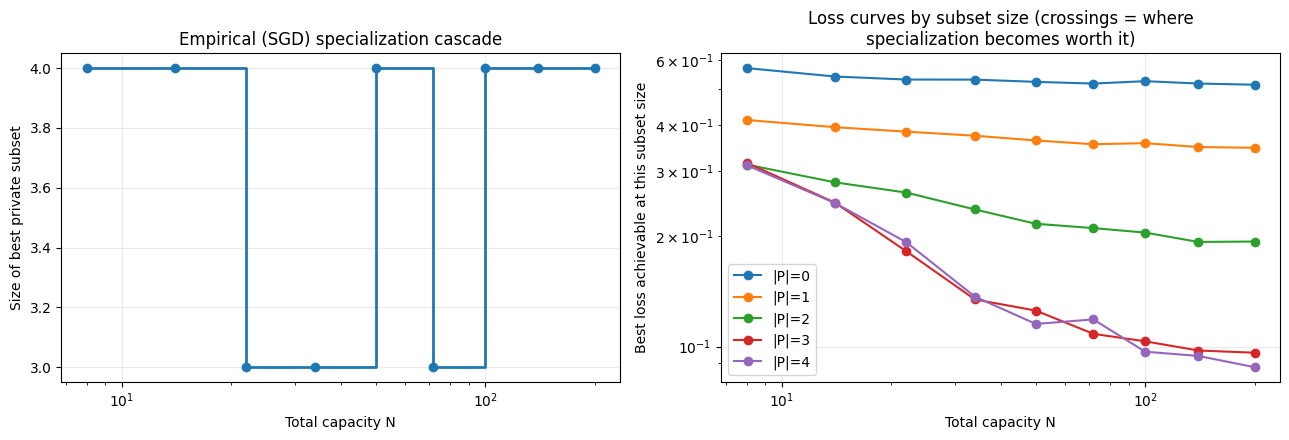

In [8]:
# Overall best subset (across all sizes) at each N, plus the loss achieved by
# the best subset of EACH size, so we can see the full nested structure.
overall_best_size = []
overall_best_P = []
loss_by_size = {r: [] for r in range(K + 1)}

for N in Ns:
    best_by_size = sweep_results[N]
    for r in range(K + 1):
        loss_by_size[r].append(best_by_size[r][0])
    r_star = min(best_by_size, key=lambda r: best_by_size[r][0])
    overall_best_size.append(r_star)
    overall_best_P.append(best_by_size[r_star][1])

print("N, overall best subset size, overall best subset:")
for N, r, P in zip(Ns, overall_best_size, overall_best_P):
    print(f"  N={N:3d}  r*={r}  P*={P}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].step(Ns, overall_best_size, where='post', linewidth=2, marker='o')
axes[0].set_xscale('log')
axes[0].set_xlabel('Total capacity N')
axes[0].set_ylabel('Size of best private subset')
axes[0].set_title('Empirical (SGD) specialization cascade')
axes[0].grid(True, alpha=0.25)

for r in range(K + 1):
    axes[1].plot(Ns, loss_by_size[r], marker='o', label=f'|P|={r}')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel('Total capacity N')
axes[1].set_ylabel('Best loss achievable at this subset size')
axes[1].set_title('Loss curves by subset size (crossings = where\nspecialization becomes worth it)')
axes[1].legend()
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()


## Section 6 — Verify the nesting and compare to the predicted order

The theory doesn't just predict *how many* languages should specialize at a
given `N` — it predicts *which ones*, in a specific order (highest `tau`
combined with highest `sigma` first). This cell checks whether the winning
subset at each size is actually a superset of the winning subset one size
smaller (a genuine nested cascade, not just a same-sized but different set
each time), and prints the order the theory predicts for direct comparison.


In [9]:
# Check: does the best subset of size r, at each N, actually CONTAIN the
# best subset of size r-1? This is the "nested cascade" property -- languages
# peel off one at a time in a consistent order, rather than the composition
# of the best subset jumping around unpredictably as N grows.

print("Nesting check (is best-size-r a superset of best-size-(r-1))?")
for N in Ns:
    best_by_size = sweep_results[N]
    sets = [set(best_by_size[r][1]) for r in range(K + 1)]
    nested = all(sets[r - 1] <= sets[r] for r in range(1, K + 1))
    print(f"  N={N:3d}  {[best_by_size[r][1] for r in range(K+1)]}  nested={nested}")

print()
print("Predicted peel-off order from (tau, sigma), highest first:")
ranked = sorted(range(K), key=lambda L: (lang_configs[L]['tau'], lang_configs[L]['sigma']), reverse=True)
print(" ", ranked, "  (i.e. language 3, then 2, then 1, then 0)")


Nesting check (is best-size-r a superset of best-size-(r-1))?
  N=  8  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N= 14  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N= 22  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N= 34  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N= 50  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N= 72  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N=100  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N=140  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True
  N=200  [(), (3,), (2, 3), (1, 2, 3), (0, 1, 2, 3)]  nested=True

Predicted peel-off order from (tau, sigma), highest first:
  [3, 2, 1, 0]   (i.e. language 3, then 2, then 1, then 0)


## What this experiment establishes (once Section 4 is run)

**If the results match the pattern seen in preliminary runs during
development** (best-of-size-1 = {3}, best-of-size-2 = {2,3}, best-of-size-3
= {1,2,3}, nested, growing with `N` in that order):

- SGD, training a real network with no access to the closed-form theory,
  rediscovers the same qualitative allocation Experiment 1 derived
  analytically.
- The peel-off order matches the theory's `(tau, epsilon)` ranking, not just
  the total count of specialized languages.
- The zero-epsilon language (language 0) is expected to show near-indifference
  between shared/private at any `N` — the theory itself predicts `N* = infinity`
  for `epsilon = 0`, so noise/ties there are a *confirmation*, not a bug.

**What this does NOT yet establish:**

- Nothing here uses real language data, tokens, or grammar — that's the next
  step (bringing the PCFG back, now informed by the two fixes above: use an
  explicit noisy-channel bottleneck for epsilon rather than encoding
  distance, and prefer hard subset comparisons over soft/gated or purely
  correlational sharing metrics).
- The private/shared split here is a global architectural choice, decided by
  comparing whole-network losses across candidate subsets — it does not yet
  show *where inside* a more realistic model such a split would live.
- Only one random task function `f(s)` and one encoder were tested. Before
  trusting the ordering as a general result (rather than a property of this
  specific task), it's worth re-running with a different `invariant_task`
  and a different `A_common` seed to confirm the same qualitative cascade
  reappears.

**Next step:** if Section 4-6 confirm the cascade, bring the PCFG grammar
back with the same two fixes (real noisy-channel epsilon, hard subset
comparison instead of a gate or correlational metric) rather than the
geometric-distance / Pearson-correlation approach used in v6-v9.
